# 04 — Vision Transformer (ViT-B/16) Fine-Tuning

**Project:** Brain MRI Image Classification and Explainable AI  
**Goal:** Fine-tune an ImageNet-pretrained Vision Transformer, select the best checkpoint using validation macro-F1, and compare ViT against the custom CNN and ResNet-18 from notebooks 02 and 03.

This notebook reuses the shared `results/model_data_split.csv`. It does not create a new split, so model comparisons remain aligned.

> **Research/education only:** This is not a clinical diagnostic tool. The dataset may contain source-specific patterns and duplicate/near-duplicate images, and reliable patient identifiers are unavailable. Metrics do not establish clinical generalization.

## What this notebook produces

- `models/vit_b16.pt` — checkpoint selected by validation macro-F1.
- `results/vit_history.csv` and `results/vit_metrics.json` — training history and experiment summary.
- `results/vit_classification_report.csv` and `results/vit_predictions.csv` — class-wise metrics and per-image probabilities.
- Confusion-matrix and learning-curve plots under `results/visualizations/`.
- An updated `results/model_comparison.csv` containing the available CNN, ResNet-18, and ViT results.

## 1. Imports and reproducibility

Install the project dependencies from the project root using `pip install -r requirements.txt`. The implementation uses `torchvision.models.vit_b_16` and its official ImageNet weights. The first pretrained run may download weights; if you cannot access the download, use `USE_PRETRAINED_WEIGHTS = False` only for a smoke test, and do not describe that run as pretrained transfer learning.

In [2]:
from pathlib import Path
import copy
import json
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError
from IPython.display import display

import sklearn
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import ViT_B_16_Weights, vit_b_16
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

torch.set_num_threads(max(1, min(4, torch.get_num_threads())))
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("scikit-learn:", sklearn.__version__)
print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.5.1+cu121
scikit-learn: 1.9.1
Device: cuda
CUDA available: True


## 2. Configuration and output paths

ViT-B/16 is substantially larger than the custom CNN. A smaller batch size is used by default on CPU. If you run out of GPU memory, lower `BATCH_SIZE` (for example, from 16 to 8 or 4). Do not resize ViT-B/16 inputs below 224×224 without deliberately changing and testing the architecture.

In [3]:
CWD = Path.cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name.lower() == "notebooks" else CWD
DATA_BASE = PROJECT_ROOT / "data"
DATASET_ROOT_OVERRIDE = None  # Example: Path(r"D:/datasets/brain-tumor-mri-dataset")
RESULTS_DIR = PROJECT_ROOT / "results"
VIS_DIR = RESULTS_DIR / "visualizations"
MODELS_DIR = PROJECT_ROOT / "models"
for folder in (RESULTS_DIR, VIS_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SPLIT_PATH = RESULTS_DIR / "model_data_split.csv"
CHECKPOINT_PATH = MODELS_DIR / "vit_b16.pt"
HISTORY_PATH = RESULTS_DIR / "vit_history.csv"
METRICS_PATH = RESULTS_DIR / "vit_metrics.json"
REPORT_PATH = RESULTS_DIR / "vit_classification_report.csv"
PREDICTIONS_PATH = RESULTS_DIR / "vit_predictions.csv"
COMPARISON_PATH = RESULTS_DIR / "model_comparison.csv"

IMG_SIZE = 224
BATCH_SIZE = 16 if DEVICE.type == "cuda" else 4
EPOCHS = 10 if DEVICE.type == "cuda" else 5
HEAD_ONLY_EPOCHS = 2
NUM_UNFROZEN_ENCODER_LAYERS = 2
HEAD_LEARNING_RATE = 5e-4
BACKBONE_LEARNING_RATE = 2e-5
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 3
NUM_WORKERS = 0
USE_PRETRAINED_WEIGHTS = True

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

print("Project root:", PROJECT_ROOT)
print("Dataset search root:", DATA_BASE)
print("Shared split manifest:", SPLIT_PATH)
print("Device:", DEVICE)
print("Batch size:", BATCH_SIZE, "| max epochs:", EPOCHS)
print("Pretrained ImageNet weights:", USE_PRETRAINED_WEIGHTS)
if DEVICE.type == "cpu":
    print("CPU detected: ViT-B/16 training can be slow. Consider a GPU runtime or reduce EPOCHS for a smoke test.")

Project root: D:\computer vision\Brain-MRI-Classification
Dataset search root: D:\computer vision\Brain-MRI-Classification\data
Shared split manifest: D:\computer vision\Brain-MRI-Classification\results\model_data_split.csv
Device: cuda
Batch size: 16 | max epochs: 10
Pretrained ImageNet weights: True


## 3. Load the shared split manifest

Run notebooks 01–03 first, especially notebook 02, which creates `results/model_data_split.csv`. This notebook reuses the saved train/validation/test assignment rather than creating a new random split. It also computes a secondary test subset that removes test images whose exact SHA-256 hash occurs in the original training data. This secondary subset is a sensitivity analysis, not a guarantee of patient-level independence.

In [4]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
TRAIN_NAMES = {"training", "train"}
TEST_NAMES = {"testing", "test"}


def class_dirs_with_images(split_dir: Path):
    if not split_dir.is_dir():
        return []
    return [
        child for child in sorted(split_dir.iterdir())
        if child.is_dir() and any(
            p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
            for p in child.rglob("*")
        )
    ]


def find_dataset_root(search_root: Path) -> Path:
    if not search_root.exists():
        raise FileNotFoundError(
            f"Dataset root not found: {search_root}. Download/extract the Kaggle dataset under data/ "
            "or change DATA_BASE in the configuration cell."
        )
    candidate_dirs = [p for p in search_root.rglob("*") if p.is_dir()]
    candidate_dirs.append(search_root)
    train_dirs = [p for p in candidate_dirs if p.name.lower() in TRAIN_NAMES and class_dirs_with_images(p)]
    test_dirs = [p for p in candidate_dirs if p.name.lower() in TEST_NAMES and class_dirs_with_images(p)]
    pairs = [(tr, te) for tr in train_dirs for te in test_dirs if tr.parent == te.parent]
    if not pairs:
        raise FileNotFoundError(
            "Could not find matching Training/Testing (or train/test) directories with class folders. "
            f"Searched: {search_root}. Check the layout documented in README.md."
        )
    pairs.sort(key=lambda pair: len(pair[0].parts) + len(pair[1].parts))
    return pairs[0][0].parent


if not SPLIT_PATH.exists():
    raise FileNotFoundError(
        f"Missing {SPLIT_PATH}. Run notebooks/02_custom_cnn.ipynb first; it creates the shared split manifest."
    )

DATASET_ROOT = Path(DATASET_ROOT_OVERRIDE).expanduser().resolve() if DATASET_ROOT_OVERRIDE else find_dataset_root(DATA_BASE)
split_df = pd.read_csv(SPLIT_PATH)
required_columns = {"model_split", "class_name", "relative_path", "sha256"}
missing_columns = required_columns - set(split_df.columns)
if missing_columns:
    raise ValueError(f"Split manifest is missing required columns: {sorted(missing_columns)}")

split_df["model_split"] = split_df["model_split"].astype(str).str.lower().str.strip()
split_df["class_name"] = split_df["class_name"].astype(str).str.lower().str.strip()
split_df["relative_path"] = split_df["relative_path"].astype(str)
split_df["sha256"] = split_df["sha256"].astype(str)
CLASS_NAMES = sorted(split_df["class_name"].dropna().unique().tolist(), key=str.casefold)
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}

expected_splits = {"train", "validation", "test"}
actual_splits = set(split_df["model_split"].unique())
if not expected_splits.issubset(actual_splits):
    raise ValueError(f"Manifest must contain {sorted(expected_splits)}; found {sorted(actual_splits)}")
if len(CLASS_NAMES) < 2:
    raise ValueError(f"Expected multiple classes; found: {CLASS_NAMES}")

split_df["path"] = split_df["relative_path"].map(lambda rel: str((DATASET_ROOT / Path(rel)).resolve()))
missing_paths = split_df.loc[~split_df["path"].map(lambda value: Path(value).is_file()), "relative_path"].tolist()
if missing_paths:
    raise FileNotFoundError(
        f"{len(missing_paths)} manifest paths were not found under {DATASET_ROOT}. "
        f"Examples: {missing_paths[:5]}. Correct DATASET_ROOT_OVERRIDE if the dataset moved."
    )

train_df = split_df.loc[split_df["model_split"] == "train"].copy().reset_index(drop=True)
val_df = split_df.loc[split_df["model_split"] == "validation"].copy().reset_index(drop=True)
test_df = split_df.loc[split_df["model_split"] == "test"].copy().reset_index(drop=True)
if any(frame.empty for frame in (train_df, val_df, test_df)):
    raise ValueError("Train, validation and test splits must all contain images.")

train_hashes = set(train_df["sha256"])
val_hashes = set(val_df["sha256"])
if train_hashes.intersection(val_hashes):
    raise ValueError("Exact SHA-256 overlap found between train and validation. Rebuild the split in notebook 02.")
if not set(CLASS_NAMES).issubset(set(train_df["class_name"])):
    raise ValueError("At least one class is missing from the training split.")

train_validation_hashes = set(
    split_df.loc[split_df["model_split"].isin(["train", "validation"]), "sha256"]
)
test_exact_filtered_df = test_df.loc[~test_df["sha256"].isin(train_validation_hashes)].copy().reset_index(drop=True)

print("Dataset root:", DATASET_ROOT)
print("Classes:", CLASS_NAMES)
print("Class mapping:", CLASS_TO_IDX)
print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Official test: {len(test_df):,}")
print(f"Exact-duplicate-filtered test: {len(test_exact_filtered_df):,}")
display(split_df.groupby(["model_split", "class_name"]).size().rename("images").reset_index())

Dataset root: D:\computer vision\Brain-MRI-Classification\data\brain-tumor-mri-dataset
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Class mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Train: 4,480 | Validation: 1,120 | Official test: 1,600
Exact-duplicate-filtered test: 1,600


,model_split,class_name,images
0,test,glioma,400
1,test,meningioma,400
2,test,notumor,400
3,test,pituitary,400
4,train,glioma,1120
5,train,meningioma,1120
6,train,notumor,1120
7,train,pituitary,1120
8,validation,glioma,280
9,validation,meningioma,280


## 4. Preprocessing and dataloaders

The input is resized to 224×224 and normalized using ImageNet statistics, matching the expected input scale for the pretrained weights. Augmentation is applied to the training partition only; validation and test transforms are deterministic.

In [5]:
TRAIN_TRANSFORM = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(degrees=8),
    transforms.RandomAffine(degrees=0, translate=(0.02, 0.02), scale=(0.97, 1.03)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
EVAL_TRANSFORM = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


class BrainMRIDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, class_to_idx: dict, transform=None):
        self.frame = frame.reset_index(drop=True).copy()
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        image_path = Path(row["path"])
        try:
            with Image.open(image_path) as image_obj:
                image = image_obj.convert("RGB")
        except (UnidentifiedImageError, OSError, ValueError) as exc:
            raise RuntimeError(f"Could not read image {image_path}: {exc}") from exc
        if self.transform is not None:
            image = self.transform(image)
        label = self.class_to_idx[row["class_name"]]
        return image, label, row["relative_path"]


train_dataset = BrainMRIDataset(train_df, CLASS_TO_IDX, TRAIN_TRANSFORM)
val_dataset = BrainMRIDataset(val_df, CLASS_TO_IDX, EVAL_TRANSFORM)
test_dataset = BrainMRIDataset(test_df, CLASS_TO_IDX, EVAL_TRANSFORM)
test_exact_filtered_dataset = BrainMRIDataset(test_exact_filtered_df, CLASS_TO_IDX, EVAL_TRANSFORM)

loader_common = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
}
train_loader = DataLoader(
    train_dataset, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), **loader_common
)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_common)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_common)
test_exact_filtered_loader = DataLoader(test_exact_filtered_dataset, shuffle=False, **loader_common)

print({
    "train": len(train_dataset),
    "validation": len(val_dataset),
    "official_test": len(test_dataset),
    "test_exact_duplicate_filtered": len(test_exact_filtered_dataset),
})

{'train': 4480, 'validation': 1120, 'official_test': 1600, 'test_exact_duplicate_filtered': 1600}


## 5. Build ViT-B/16 and set the fine-tuning stages

The first stage trains only the four-class classification head. The second stage unfreezes the final two Transformer encoder blocks, the final encoder layer normalization, and the classification head. This is a practical compute-conscious fine-tuning strategy; it is not guaranteed to be optimal, so document any changes you make.

If pretrained weights cannot be downloaded, the notebook raises an actionable error rather than silently substituting random initialization.

In [6]:
if USE_PRETRAINED_WEIGHTS:
    try:
        weights = ViT_B_16_Weights.DEFAULT
        model = vit_b_16(weights=weights)
        weights_name = "ViT_B_16_Weights.DEFAULT (ImageNet pretrained)"
    except Exception as exc:
        raise RuntimeError(
            "Could not load the pretrained ViT-B/16 weights. Check internet access/cache, or set "
            "USE_PRETRAINED_WEIGHTS = False for a smoke test only. Do not report an unpretrained run as transfer learning."
        ) from exc
else:
    model = vit_b_16(weights=None)
    weights_name = "None (random initialization; smoke test only)"

model.heads.head = nn.Linear(model.heads.head.in_features, len(CLASS_NAMES))

# Stage 1: freeze the backbone and train only the replacement classification head.
for parameter in model.parameters():
    parameter.requires_grad = False
for parameter in model.heads.parameters():
    parameter.requires_grad = True

model = model.to(DEVICE)
criterion = nn.CrossEntropyLoss()


def freeze_backbone_train_head(model):
    for parameter in model.parameters():
        parameter.requires_grad = False
    for parameter in model.heads.parameters():
        parameter.requires_grad = True


def unfreeze_final_encoder_layers(model, n_layers=2):
    for parameter in model.parameters():
        parameter.requires_grad = False
    for parameter in model.heads.parameters():
        parameter.requires_grad = True
    encoder_layers = list(model.encoder.layers.children())
    n_layers = min(max(1, int(n_layers)), len(encoder_layers))
    for layer in encoder_layers[-n_layers:]:
        for parameter in layer.parameters():
            parameter.requires_grad = True
    for parameter in model.encoder.ln.parameters():
        parameter.requires_grad = True
    return n_layers


def build_head_optimizer(model):
    params = [p for p in model.heads.parameters() if p.requires_grad]
    return torch.optim.AdamW(params, lr=HEAD_LEARNING_RATE, weight_decay=WEIGHT_DECAY)


def build_finetune_optimizer(model):
    backbone_params = [
        p for name, p in model.named_parameters()
        if p.requires_grad and not name.startswith("heads.")
    ]
    head_params = [p for p in model.heads.parameters() if p.requires_grad]
    return torch.optim.AdamW(
        [
            {"params": backbone_params, "lr": BACKBONE_LEARNING_RATE},
            {"params": head_params, "lr": HEAD_LEARNING_RATE},
        ],
        weight_decay=WEIGHT_DECAY,
    )

num_parameters = sum(p.numel() for p in model.parameters())
head_trainable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Architecture: torchvision ViT-B/16")
print("Weights:", weights_name)
print(f"Total parameters: {num_parameters:,}")
print(f"Trainable parameters during head warm-up: {head_trainable_parameters:,}")
print("Classification classes:", CLASS_NAMES)
if HEAD_ONLY_EPOCHS < 0 or HEAD_ONLY_EPOCHS >= EPOCHS:
    warnings.warn("HEAD_ONLY_EPOCHS should normally be between 0 and EPOCHS - 1 so backbone fine-tuning occurs.")

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to C:\Users\adity/.cache\torch\hub\checkpoints\vit_b_16-c867db91.pth
100%|██████████| 330M/330M [00:14<00:00, 23.9MB/s] 


Architecture: torchvision ViT-B/16
Weights: ViT_B_16_Weights.DEFAULT (ImageNet pretrained)
Total parameters: 85,801,732
Trainable parameters during head warm-up: 3,076
Classification classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


## 6. Training and evaluation helpers

The checkpoint is selected with **validation macro-F1**, not test performance. The evaluator reports macro-averaged metrics and measures forward-pass latency separately from data loading.

In [7]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    total = 0
    for images, labels, _ in tqdm(loader, desc="Train", leave=False):
        images = images.to(device, non_blocking=(device.type == "cuda"))
        labels = labels.to(device, non_blocking=(device.type == "cuda"))
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        batch_size = labels.size(0)
        running_loss += float(loss.detach().item()) * batch_size
        total += batch_size
    return running_loss / max(total, 1)


def evaluate_model(model, loader, criterion, device, class_names):
    model.eval()
    running_loss = 0.0
    total = 0
    y_true, y_pred, y_prob, paths = [], [], [], []
    forward_seconds = 0.0
    with torch.inference_mode():
        for images, labels, batch_paths in tqdm(loader, desc="Evaluate", leave=False):
            images = images.to(device, non_blocking=(device.type == "cuda"))
            labels = labels.to(device, non_blocking=(device.type == "cuda"))
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            start_time = time.perf_counter()
            logits = model(images)
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            forward_seconds += time.perf_counter() - start_time

            loss = criterion(logits, labels)
            probabilities = torch.softmax(logits, dim=1)
            predictions = probabilities.argmax(dim=1)
            batch_size = labels.size(0)
            running_loss += float(loss.item()) * batch_size
            total += batch_size
            y_true.extend(labels.cpu().numpy().tolist())
            y_pred.extend(predictions.cpu().numpy().tolist())
            y_prob.extend(probabilities.cpu().numpy().tolist())
            paths.extend(list(batch_paths))

    if total == 0:
        raise ValueError("Cannot evaluate an empty dataset.")
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    y_prob = np.asarray(y_prob, dtype=float)
    labels_all = list(range(len(class_names)))
    metrics = {
        "loss": float(running_loss / total),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, labels=labels_all, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, labels=labels_all, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, labels=labels_all, average="macro", zero_division=0)),
        "num_images": int(total),
        "forward_latency_ms_per_image": float(1000.0 * forward_seconds / total),
    }
    try:
        metrics["roc_auc_ovr_macro"] = float(
            roc_auc_score(y_true, y_prob, labels=labels_all, multi_class="ovr", average="macro")
        )
    except ValueError as exc:
        metrics["roc_auc_ovr_macro"] = None
        metrics["roc_auc_note"] = str(exc)
    return metrics, y_true, y_pred, y_prob, paths


def build_prediction_frame(frame, y_true, y_pred, y_prob, class_names, evaluation_name):
    output = pd.DataFrame({
        "evaluation": evaluation_name,
        "relative_path": frame["relative_path"].to_numpy(),
        "true_class": [class_names[index] for index in y_true],
        "predicted_class": [class_names[index] for index in y_pred],
        "correct": (y_true == y_pred),
    })
    for class_idx, class_name in enumerate(class_names):
        output[f"probability_{class_name}"] = y_prob[:, class_idx]
    return output


def save_confusion_matrix(y_true, y_pred, class_names, title, output_path):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(cm, interpolation="nearest")
    ax.set_title(title)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    ticks = np.arange(len(class_names))
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels(class_names, rotation=35, ha="right")
    ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    threshold = cm.max() / 2 if cm.size else 0
    for row_idx in range(cm.shape[0]):
        for col_idx in range(cm.shape[1]):
            ax.text(col_idx, row_idx, str(cm[row_idx, col_idx]), ha="center", va="center",
                    color="white" if cm[row_idx, col_idx] > threshold else "black")
    plt.tight_layout()
    plt.savefig(output_path, dpi=160, bbox_inches="tight")
    plt.show()
    return cm


criterion = nn.CrossEntropyLoss()
optimizer = build_head_optimizer(model)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=1)
print("Training/evaluation helpers ready.")

Training/evaluation helpers ready.


## 7. Fine-tune the ViT and select the best checkpoint

The model trains the head first, then unfreezes the final encoder layers. Validation macro-F1 controls learning-rate scheduling, checkpoint selection, and early stopping. The test set is not used during training.

In [8]:
history = []
best_val_f1 = -1.0
best_epoch = None
epochs_without_improvement = 0
fine_tuning_started = False
unfrozen_layers_count = 0

for epoch in range(1, EPOCHS + 1):
    # At this boundary, switch from head-only warm-up to partial encoder fine-tuning.
    if not fine_tuning_started and epoch > HEAD_ONLY_EPOCHS:
        unfrozen_layers_count = unfreeze_final_encoder_layers(model, NUM_UNFROZEN_ENCODER_LAYERS)
        optimizer = build_finetune_optimizer(model)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=1
        )
        fine_tuning_started = True
        print(f"\nUnfroze the final {unfrozen_layers_count} Transformer encoder blocks plus final LayerNorm and head.")

    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
    val_metrics, y_val, pred_val, prob_val, val_paths = evaluate_model(
        model, val_loader, criterion, DEVICE, CLASS_NAMES
    )
    val_f1 = float(val_metrics["f1_macro"])
    scheduler.step(val_f1)

    epoch_row = {
        "epoch": epoch,
        "train_loss": float(train_loss),
        "validation_loss": float(val_metrics["loss"]),
        "validation_accuracy": float(val_metrics["accuracy"]),
        "validation_macro_f1": val_f1,
        "validation_macro_recall": float(val_metrics["recall_macro"]),
        "learning_rates": ";".join(f"{group['lr']:.8g}" for group in optimizer.param_groups),
        "stage": "partial_finetune" if fine_tuning_started else "head_only",
    }
    history.append(epoch_row)
    history_df = pd.DataFrame(history)
    history_df.to_csv(HISTORY_PATH, index=False)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | stage={epoch_row['stage']} | "
        f"train_loss={train_loss:.4f} | val_loss={val_metrics['loss']:.4f} | "
        f"val_acc={val_metrics['accuracy']:.4f} | val_macro_f1={val_f1:.4f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class_names": CLASS_NAMES,
                "class_to_idx": CLASS_TO_IDX,
                "best_epoch": int(best_epoch),
                "best_validation_macro_f1": float(best_val_f1),
                "weights": weights_name,
                "seed": int(SEED),
                "img_size": int(IMG_SIZE),
                "imagenet_mean": list(IMAGENET_MEAN),
                "imagenet_std": list(IMAGENET_STD),
                "unfrozen_encoder_layers": int(unfrozen_layers_count),
            },
            CHECKPOINT_PATH,
        )
        print("  Saved new best checkpoint:", CHECKPOINT_PATH)
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(f"Early stopping after {epoch} epochs; best epoch was {best_epoch}.")
        break

if not CHECKPOINT_PATH.exists():
    raise RuntimeError("No checkpoint was saved. Check the training loop and validation data.")

history_df = pd.DataFrame(history)
history_df.to_csv(HISTORY_PATH, index=False)
print("Best epoch:", best_epoch)
print("Best validation macro-F1:", round(best_val_f1, 4))
print("Saved history:", HISTORY_PATH)

Epoch 01/10 | stage=head_only | train_loss=0.5625 | val_loss=0.3983 | val_acc=0.8634 | val_macro_f1=0.8611
  Saved new best checkpoint: D:\computer vision\Brain-MRI-Classification\models\vit_b16.pt


Epoch 02/10 | stage=head_only | train_loss=0.3468 | val_loss=0.3240 | val_acc=0.8866 | val_macro_f1=0.8876
  Saved new best checkpoint: D:\computer vision\Brain-MRI-Classification\models\vit_b16.pt

Unfroze the final 2 Transformer encoder blocks plus final LayerNorm and head.


Epoch 03/10 | stage=partial_finetune | train_loss=0.2582 | val_loss=0.2156 | val_acc=0.9152 | val_macro_f1=0.9168
  Saved new best checkpoint: D:\computer vision\Brain-MRI-Classification\models\vit_b16.pt


Epoch 04/10 | stage=partial_finetune | train_loss=0.1569 | val_loss=0.1607 | val_acc=0.9375 | val_macro_f1=0.9382
  Saved new best checkpoint: D:\computer vision\Brain-MRI-Classification\models\vit_b16.pt


Epoch 05/10 | stage=partial_finetune | train_loss=0.1201 | val_loss=0.1525 | val_acc=0.9420 | val_macro_f1=0.9417
  Saved new best checkpoint: D:\computer vision\Brain-MRI-Classification\models\vit_b16.pt


Epoch 06/10 | stage=partial_finetune | train_loss=0.0807 | val_loss=0.1316 | val_acc=0.9536 | val_macro_f1=0.9543
  Saved new best checkpoint: D:\computer vision\Brain-MRI-Classification\models\vit_b16.pt


Epoch 07/10 | stage=partial_finetune | train_loss=0.0550 | val_loss=0.0966 | val_acc=0.9643 | val_macro_f1=0.9644
  Saved new best checkpoint: D:\computer vision\Brain-MRI-Classification\models\vit_b16.pt


Epoch 08/10 | stage=partial_finetune | train_loss=0.0540 | val_loss=0.1122 | val_acc=0.9616 | val_macro_f1=0.9617


Epoch 09/10 | stage=partial_finetune | train_loss=0.0409 | val_loss=0.1041 | val_acc=0.9670 | val_macro_f1=0.9669
  Saved new best checkpoint: D:\computer vision\Brain-MRI-Classification\models\vit_b16.pt


Epoch 10/10 | stage=partial_finetune | train_loss=0.0381 | val_loss=0.0996 | val_acc=0.9696 | val_macro_f1=0.9695
  Saved new best checkpoint: D:\computer vision\Brain-MRI-Classification\models\vit_b16.pt
Best epoch: 10
Best validation macro-F1: 0.9695
Saved history: D:\computer vision\Brain-MRI-Classification\results\vit_history.csv


## 8. Plot learning curves

Use validation curves to inspect convergence and possible overfitting. The checkpoint has already been selected using validation macro-F1. Do not change the model configuration based on the final test scores.

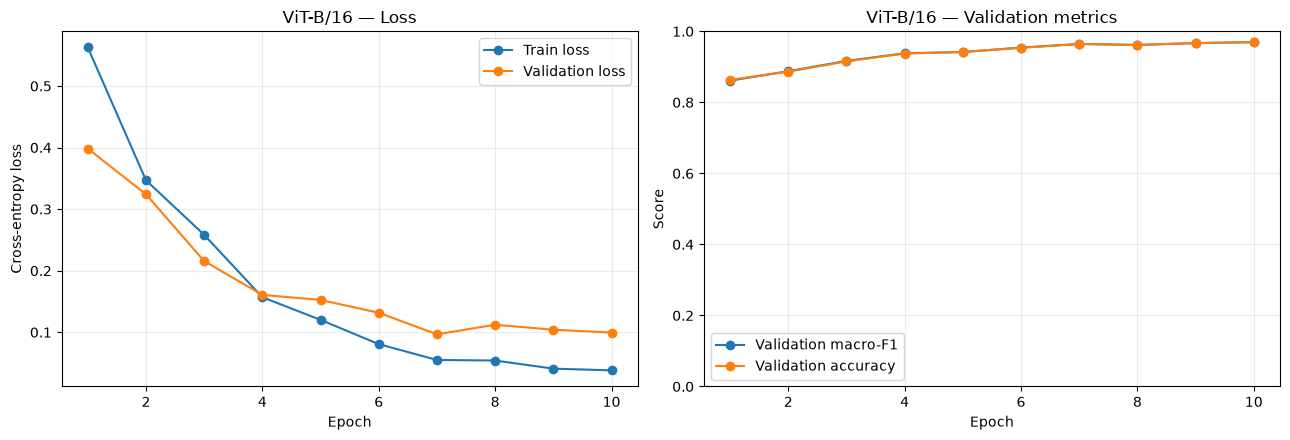

Saved learning curves: D:\computer vision\Brain-MRI-Classification\results\visualizations\vit_learning_curves.png


In [9]:
history_df = pd.read_csv(HISTORY_PATH)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train loss")
axes[0].plot(history_df["epoch"], history_df["validation_loss"], marker="o", label="Validation loss")
axes[0].set_title("ViT-B/16 — Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(history_df["epoch"], history_df["validation_macro_f1"], marker="o", label="Validation macro-F1")
axes[1].plot(history_df["epoch"], history_df["validation_accuracy"], marker="o", label="Validation accuracy")
axes[1].set_title("ViT-B/16 — Validation metrics")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
learning_curves_path = VIS_DIR / "vit_learning_curves.png"
plt.savefig(learning_curves_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved learning curves:", learning_curves_path)

## 9. Restore the best checkpoint and evaluate the official test set

Only now do we evaluate the official test partition. We also report a secondary result on the subset with no exact SHA-256 match in the original training data. Since the filtering is based on exact hashes, it does not remove all near-duplicates.

In [10]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)
if checkpoint["class_names"] != CLASS_NAMES:
    raise ValueError("Checkpoint class mapping does not match the current manifest. Retrain or use the original split.")
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

num_trainable_after_finetune = sum(p.numel() for p in model.parameters() if p.requires_grad)

official_metrics, y_test, pred_test, prob_test, test_paths = evaluate_model(
    model, test_loader, criterion, DEVICE, CLASS_NAMES
)
official_predictions = build_prediction_frame(
    test_df, y_test, pred_test, prob_test, CLASS_NAMES, "official_test"
)
print("Official test metrics:")
display(pd.DataFrame([official_metrics]).T.rename(columns={0: "value"}))

if len(test_exact_filtered_dataset) > 0:
    filtered_metrics, y_filtered, pred_filtered, prob_filtered, filtered_paths = evaluate_model(
        model, test_exact_filtered_loader, criterion, DEVICE, CLASS_NAMES
    )
    filtered_predictions = build_prediction_frame(
        test_exact_filtered_df, y_filtered, pred_filtered, prob_filtered,
        CLASS_NAMES, "test_exact_duplicate_filtered"
    )
    print("Exact-duplicate-filtered test metrics:")
    display(pd.DataFrame([filtered_metrics]).T.rename(columns={0: "value"}))
else:
    filtered_metrics = None
    y_filtered = pred_filtered = prob_filtered = filtered_paths = None
    filtered_predictions = pd.DataFrame()
    print("No images remain after exact-duplicate filtering; secondary test metrics are unavailable.")

Official test metrics:


,value
loss,0.296543
accuracy,0.939375
balanced_accuracy,0.939375
precision_macro,0.940384
recall_macro,0.939375
f1_macro,0.938366
num_images,1600.000000
forward_latency_ms_per_image,30.959198
roc_auc_ovr_macro,0.990145


Exact-duplicate-filtered test metrics:


,value
loss,0.296543
accuracy,0.939375
balanced_accuracy,0.939375
precision_macro,0.940384
recall_macro,0.939375
f1_macro,0.938366
num_images,1600.000000
forward_latency_ms_per_image,31.364144
roc_auc_ovr_macro,0.990145


## 10. Class-wise report, confusion matrices and prediction export

Inspect per-class recall and errors as well as overall metrics. Saved per-image probabilities make it possible to compare models and review difficult examples later.

,precision,recall,f1-score,support
glioma,0.9599,0.8375,0.8945,400.0000
meningioma,0.9163,0.9300,0.9231,400.0000
notumor,0.9195,1.0000,0.9581,400.0000
pituitary,0.9659,0.9900,0.9778,400.0000
accuracy,0.9394,0.9394,0.9394,0.9394
macro avg,0.9404,0.9394,0.9384,1600.0000
weighted avg,0.9404,0.9394,0.9384,1600.0000


Saved class-wise report: D:\computer vision\Brain-MRI-Classification\results\vit_classification_report.csv


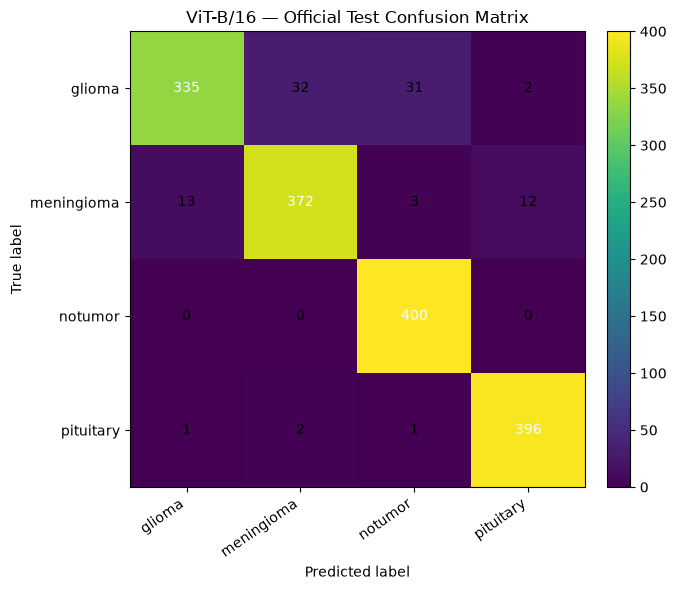

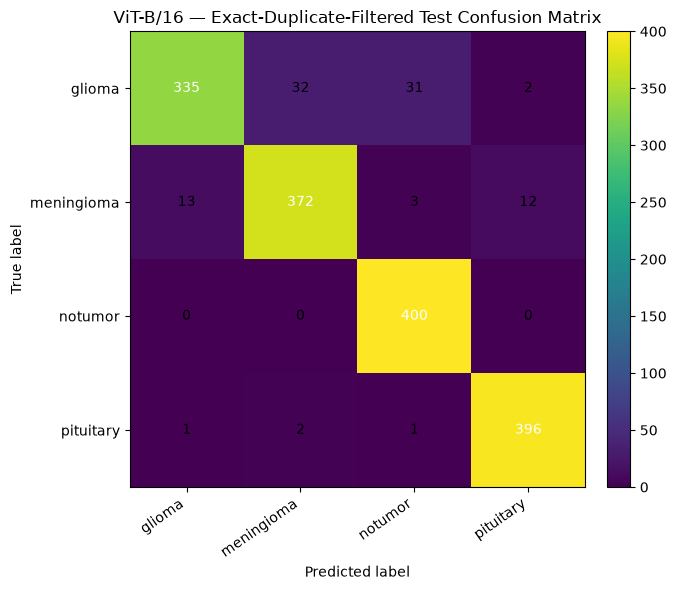

Saved predictions: D:\computer vision\Brain-MRI-Classification\results\vit_predictions.csv


,evaluation,relative_path,true_class,predicted_class,correct,probability_glioma,probability_meningioma,probability_notumor,probability_pituitary
0,official_test,Testing/glioma/Te-gl_1.jpg,glioma,notumor,False,0.311212,1.348048e-04,0.688553,1.009674e-04
1,official_test,Testing/glioma/Te-gl_10.jpg,glioma,glioma,True,0.999995,6.352381e-08,0.000005,5.733882e-10
2,official_test,Testing/glioma/Te-gl_100.jpg,glioma,glioma,True,0.999872,1.942826e-06,0.000126,7.281726e-09
3,official_test,Testing/glioma/Te-gl_101.jpg,glioma,glioma,True,0.969823,2.602918e-02,0.000648,3.500119e-03
4,official_test,Testing/glioma/Te-gl_102.jpg,glioma,notumor,False,0.047828,1.447305e-04,0.949451,2.576331e-03
5,official_test,Testing/glioma/Te-gl_103.jpg,glioma,glioma,True,0.619238,2.031055e-03,0.378725,5.365645e-06
6,official_test,Testing/glioma/Te-gl_104.jpg,glioma,glioma,True,0.994717,5.251311e-03,0.000011,2.110249e-05
7,official_test,Testing/glioma/Te-gl_105.jpg,glioma,glioma,True,0.999996,1.304969e-06,0.000003,2.682678e-08
8,official_test,Testing/glioma/Te-gl_106.jpg,glioma,meningioma,False,0.002526,9.820551e-01,0.015418,1.305228e-06
9,official_test,Testing/glioma/Te-gl_107.jpg,glioma,glioma,True,0.999726,2.015848e-04,0.000072,5.083015e-08


In [11]:
class_report = classification_report(
    y_test, pred_test,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
class_report_df = pd.DataFrame(class_report).T
class_report_df.to_csv(REPORT_PATH, index=True)
display(class_report_df.round(4))
print("Saved class-wise report:", REPORT_PATH)

save_confusion_matrix(
    y_test, pred_test, CLASS_NAMES,
    "ViT-B/16 — Official Test Confusion Matrix",
    VIS_DIR / "vit_confusion_matrix_official_test.png",
)
if filtered_metrics is not None:
    save_confusion_matrix(
        y_filtered, pred_filtered, CLASS_NAMES,
        "ViT-B/16 — Exact-Duplicate-Filtered Test Confusion Matrix",
        VIS_DIR / "vit_confusion_matrix_exact_filtered_test.png",
    )

prediction_parts = [official_predictions]
if not filtered_predictions.empty:
    prediction_parts.append(filtered_predictions)
predictions_df = pd.concat(prediction_parts, ignore_index=True)
predictions_df.to_csv(PREDICTIONS_PATH, index=False)
print("Saved predictions:", PREDICTIONS_PATH)
display(predictions_df.head(10))

## 11. Compare ViT with the custom CNN and ResNet-18

Notebook 03 writes `results/model_comparison.csv`. This cell preserves existing model rows, removes any old ViT rows from a previous run, and appends the current ViT results. If the comparison file does not exist, it creates a ViT-only file; run notebooks 02 and 03 to get the full three-model comparison.

In [12]:
metric_keys = [
    "accuracy", "balanced_accuracy", "precision_macro", "recall_macro", "f1_macro",
    "roc_auc_ovr_macro", "forward_latency_ms_per_image", "num_images",
]
comparison_rows = []
if COMPARISON_PATH.exists():
    try:
        existing_comparison = pd.read_csv(COMPARISON_PATH)
        if {"model", "evaluation"}.issubset(existing_comparison.columns):
            existing_comparison = existing_comparison.loc[
                existing_comparison["model"].astype(str).str.lower() != "vit-b/16"
            ]
            comparison_rows.extend(existing_comparison.to_dict(orient="records"))
        else:
            warnings.warn("Existing model_comparison.csv has an unexpected schema; rebuilding it with ViT rows only.")
    except (OSError, pd.errors.ParserError) as exc:
        warnings.warn(f"Could not read existing model comparison: {exc}; rebuilding it with ViT rows only.")

comparison_rows.append({
    "model": "ViT-B/16",
    "evaluation": "official_test",
    **{key: official_metrics.get(key) for key in metric_keys},
})
if filtered_metrics is not None:
    comparison_rows.append({
        "model": "ViT-B/16",
        "evaluation": "test_exact_duplicate_filtered",
        **{key: filtered_metrics.get(key) for key in metric_keys},
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(COMPARISON_PATH, index=False)
display(comparison_df.round(4))
print("Saved model comparison:", COMPARISON_PATH)

,model,evaluation,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro,forward_latency_ms_per_image,num_images
0,Custom CNN,official_test,0.8800,0.8800,0.8950,0.8800,0.8798,0.9635,3.0180,1600
1,Custom CNN,test_exact_duplicate_filtered,0.8800,0.8800,0.8950,0.8800,0.8798,0.9635,3.1460,1600
2,ResNet-18,official_test,0.9412,0.9412,0.9464,0.9412,0.9401,0.9882,2.5967,1600
3,ResNet-18,test_exact_duplicate_filtered,0.9412,0.9412,0.9464,0.9412,0.9401,0.9882,2.4020,1600
4,ViT-B/16,official_test,0.9394,0.9394,0.9404,0.9394,0.9384,0.9901,30.9592,1600
5,ViT-B/16,test_exact_duplicate_filtered,0.9394,0.9394,0.9404,0.9394,0.9384,0.9901,31.3641,1600


Saved model comparison: D:\computer vision\Brain-MRI-Classification\results\model_comparison.csv


## 12. Export experiment summary

The JSON summary captures configuration, checkpoint selection, split sizes, and final metrics. Keep the results generated by your own run; do not copy numbers from another repository.

In [13]:
summary = {
    "model": "torchvision_vit_b_16",
    "seed": int(SEED),
    "class_names": CLASS_NAMES,
    "class_to_idx": CLASS_TO_IDX,
    "weights": weights_name,
    "dataset_root_relative_to_project": (
        str(DATASET_ROOT.relative_to(PROJECT_ROOT))
        if DATASET_ROOT.is_relative_to(PROJECT_ROOT) else str(DATASET_ROOT)
    ),
    "split_manifest": str(SPLIT_PATH.relative_to(PROJECT_ROOT)),
    "split_sizes": {
        "train": int(len(train_df)),
        "validation": int(len(val_df)),
        "official_test": int(len(test_df)),
        "test_exact_duplicate_filtered": int(len(test_exact_filtered_df)),
    },
    "validation_selection": {
        "checkpoint_metric": "validation macro-F1",
        "best_epoch": int(checkpoint["best_epoch"]),
        "best_validation_macro_f1": float(checkpoint["best_validation_macro_f1"]),
        "head_only_epochs": int(HEAD_ONLY_EPOCHS),
        "unfrozen_encoder_layers": int(checkpoint["unfrozen_encoder_layers"]),
    },
    "training_config": {
        "img_size": int(IMG_SIZE),
        "batch_size": int(BATCH_SIZE),
        "epochs_requested": int(EPOCHS),
        "epochs_completed": int(len(history_df)),
        "head_learning_rate": float(HEAD_LEARNING_RATE),
        "backbone_learning_rate": float(BACKBONE_LEARNING_RATE),
        "weight_decay": float(WEIGHT_DECAY),
        "early_stopping_patience": int(EARLY_STOPPING_PATIENCE),
        "device": str(DEVICE),
        "num_parameters": int(num_parameters),
        "trainable_parameters_after_finetune": int(num_trainable_after_finetune),
        "imagenet_mean": list(IMAGENET_MEAN),
        "imagenet_std": list(IMAGENET_STD),
    },
    "best_checkpoint_path": str(CHECKPOINT_PATH.relative_to(PROJECT_ROOT)),
    "official_test_metrics": official_metrics,
    "exact_duplicate_filtered_test_metrics": filtered_metrics,
    "data_quality_notes": [
        "Reused the train/validation/test manifest from notebook 02.",
        "Checkpoint and early stopping were selected using validation macro-F1; test data did not guide training.",
        "The exact-duplicate-filtered test subset removes test hashes present in the train + validation manifest.",
        "Exact-hash filtering does not remove all near-duplicates or establish patient-level independence.",
        "This is an educational experiment, not a clinically validated diagnostic model.",
    ],
}
METRICS_PATH.write_text(json.dumps(summary, indent=2, allow_nan=False), encoding="utf-8")
print("Saved experiment summary:", METRICS_PATH)
display(pd.DataFrame([{
    "model": "ViT-B/16",
    "best_epoch": checkpoint["best_epoch"],
    "best_validation_macro_f1": checkpoint["best_validation_macro_f1"],
    "official_test_accuracy": official_metrics["accuracy"],
    "official_test_macro_f1": official_metrics["f1_macro"],
    "official_test_macro_recall": official_metrics["recall_macro"],
}]).round(4))

Saved experiment summary: D:\computer vision\Brain-MRI-Classification\results\vit_metrics.json


,model,best_epoch,best_validation_macro_f1,official_test_accuracy,official_test_macro_f1,official_test_macro_recall
0,ViT-B/16,10,0.9695,0.9394,0.9384,0.9394


## 13. Before moving to notebook 05

- [ ] Notebook 02 created `results/model_data_split.csv`, and notebooks 02–04 use that same manifest.
- [ ] The class mapping matches the CNN and ResNet experiments.
- [ ] The checkpoint was chosen using validation macro-F1 only.
- [ ] The run's pretrained-weight status is recorded correctly.
- [ ] Official and exact-duplicate-filtered results are reported separately.
- [ ] `results/model_comparison.csv` has rows for Custom CNN, ResNet-18, and ViT-B/16 after notebooks 02–04 are run.
- [ ] You inspected per-class errors and did not interpret Grad-CAM/attention visualizations as proof of medical reasoning.

Next: `05_clip_blip_experiments.ipynb` adds a separate CLIP zero-shot baseline and optional BLIP captioning experiment.